<a href="https://colab.research.google.com/github/herakwon1124/CUDA1/blob/main/CUDA_reproduction_GPU.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## CUDA Reproduction — Perishable Inventory Value Iteration

### Notebook roadmap
1. CUDA environment and experiment parameters
2. Poisson demand and inventory-capped sales
3. GPU Bellman update for a single product
4. **Experiment A:** Single product, `M=2, Q=9` (GPU)
5. **Experiment B:** Single product, `M=3, Q=15` (GPU)
6. Two-product model with one-way substitution from B to A
7. **Experiment C:** Two products, `Qa=Qb=10` (GPU)
8. Monte Carlo policy evaluation over 400,000 simulated days (CPU)
9. CPU/GPU validation, timing, and interpretation

**Implementation note:** The value-iteration Bellman updates run on an **NVIDIA GPU using Numba CUDA**. Probability tables are prepared on the CPU and transferred once to the GPU. Simulation remains sequential on the CPU because each day's inventory depends on the preceding day.


In [7]:
%pip install numpy scipy numba numba-cuda matplotlib pandas

- `numba.cuda`: compiles GPU kernels and launches parallel threads.
- `cuda.to_device(...)`: transfers arrays from CPU memory to GPU memory.
- `cuda.grid(1)`: assigns one index to each GPU thread.
- `cuda.synchronize()`: waits for GPU work to finish before timing.

In [8]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import poisson, binom
from numba import cuda
from IPython.display import display

MU_A = MU_B = 5.0 #mean daily demand
PRICE_A = PRICE_B = 1.0 #unit selling price
COST_A = COST_B = 0.5 #unit ordering cost
GAMMA = 0.5 #substitution probability(B to A)
EPSILON = 1e-4 #convergence tolerance
SEED = 123

print("NumPy:", np.__version__)
print("CUDA available:", cuda.is_available())
cuda.detect()


NumPy: 2.4.6
CUDA available: True
Found 1 CUDA devices
id 0                Tesla T4                              [SUPPORTED]
                      Compute Capability: 7.5
                           PCI Device ID: 4
                              PCI Bus ID: 0
                                    UUID: GPU-5813aac4-e96f-a84b-6999-6e7b73c74dbb
                                Watchdog: Disabled
             FP32/FP64 Performance Ratio: 32
                            FP16 Support: Yes
                            BF16 Support: No
                             FP8 Support: No
Summary:
	1/1 devices are supported


True

## 1. Poisson demand and inventory-capped sales

Daily demand is modeled as $(D\sim\mathrm{Poisson}(\mu))$. With $y$ units available, realized sales are $(S=\min(D,y))$.

The following functions calculate the probability of each possible sales quantity:

- `poisson.pmf(d, mu)`: P(D=y)
- `poisson.sf(y-1, mu)`: P(D>=y)
- `capped_poisson(mu, y)`: array([P(0), P(1), ... P(y)])


In [9]:
def capped_poisson(mu, cap):
    if cap==0:return np.array([1.])
    return np.r_[poisson.pmf(np.arange(cap),mu),poisson.sf(cap-1,mu)] #concatenate array of probabilities P(0), P(1), ... P(D>=cap)

,sales,probability
0,0,0.006738
1,1,0.033690
2,2,0.084224
3,3,0.875348


Probability sum: 1.0


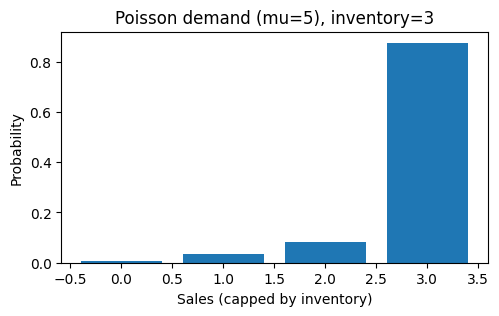

In [10]:
y = 3
sales_probs = capped_poisson(5.0, y)
display(pd.DataFrame({"sales": range(y+1), "probability": sales_probs}))
print("Probability sum:", sales_probs.sum())
plt.figure(figsize=(5.5,3))
plt.bar(range(y+1), sales_probs)
plt.xlabel("Sales (capped by inventory)"); plt.ylabel("Probability")
plt.title("Poisson demand (mu=5), inventory="+str(y))
plt.show()


## 2. Single-product model: state and GPU Bellman update

For shelf life `M=2`, the state is `(old, fresh)`. Orders arrive the following day, and products are sold FIFO.

### Bellman Update

$$
V_{k+1}(I)=\max_{q\in A(I)}
\left[R(I,q)+\mathbb{E}[V_k(I')]\right]
$$

where:

- `I`: Current inventory state.
- `q`: Order quantity.
- `R(I,q)`: Expected immediate profit (sales revenue minus ordering cost).
- `I'`: Next inventory state after demand and FIFO inventory updates.
- `V_k(I')`: Previous iteration's value of the next state.

$$
V_{k+1}(I)=s\,\mathbb{E}[S\mid I]+\max_{0\le q\le Q}\left[-cq+\sum_{d=0}^{Y}P(S=d\mid Y)V_k(F(I,q,d))\right]
$$

### GPU Implementation

- `single_update_gpu`: One GPU thread per state; evaluates all feasible orders.
- `W` and `V`: Previous and updated value functions.
- `increments`: Value changes used for convergence checking.
- `policy[j]`: Optimal order quantity for state `j`.

Each GPU thread evaluates all feasible orders for one inventory state.

In [11]:
def solve_single(M=2, Q=9, mu=5., s=1., c=.5,
                 epsilon=EPSILON, max_iter=120):

    # 1. Generate inventory states and demand probabilities

    # Generate all possible inventory states
    # For M=2 and Q=9, there are (Q+1)^M = 100 states
    states = np.array([
        np.unravel_index(j, (Q+1,)*M)
        for j in range((Q+1)**M)
    ], dtype=np.int32)

    # ps[y, d] = P(Sales=d | Total inventory=y)
    # The maximum total inventory is Q*M.
    ps = np.zeros((Q*M+1, Q*M+1), dtype=np.float64)

    # Store expected sales for each total inventory level
    expected = np.zeros(Q*M+1, dtype=np.float64)

    for y in range(Q*M+1):
        p = capped_poisson(mu, y)
        ps[y, :y+1] = p # Store the probability distribution for inventory y

        expected[y] = np.arange(y+1) @ p # Calculate expected sales: E[Sales] = sum(d * P(Sales=d))


    # 2. Transfer fixed inputs to GPU memory(copy from CPU to GPU)

    d_states = cuda.to_device(states) #inventory states
    d_ps = cuda.to_device(ps) #sales probabilities
    d_expected = cuda.to_device(expected) #expected sales

    n = len(states) #number of inventory states

    # W: Previous iteration's value function
    d_w = cuda.to_device(
        np.zeros(n, dtype=np.float64)
    )

    # V: Updated value function
    d_v = cuda.device_array(n, dtype=np.float64)

    # Store the optimal order quantity for each state
    d_policy = cuda.device_array(n, dtype=np.int32)

    # Store the value increment V-W for each state
    d_inc = cuda.device_array(n, dtype=np.float64)


    # 3. Configure GPU execution

    threads = 128 # Number of GPU threads per block

    # Calculate the number of blocks required for all states, Each thread processes one inventory state
    blocks = (n + threads - 1) // threads

    spans, gains = [], []

    cuda.synchronize()  # Ensure all GPU operations have completed

    # Start measuring the Bellman iteration runtime
    t0 = time.perf_counter()


    # 4. Run value iteration on the GPU

    for iteration in range(max_iter):

        # Launch the GPU Bellman update kernel
        # Each thread evaluates all feasible order quantities for one inventory state
        single_update_gpu[blocks, threads](
            d_states, d_ps, d_expected,
            d_w, d_v, d_policy, d_inc,
            Q, M, s, c
        )


        # 5. Check convergence on the CPU

        delta = d_inc.copy_to_host() # Copy value increments from GPU to CPU

        # Calculate the span of value increments
        # span = max(V-W) - min(V-W)
        span = float(delta.max() - delta.min())

        spans.append(span)
        gains.append(float(delta.mean()))

        if span < epsilon:
            break


        # 6. Prepare the next iteration

        # Swap W and V without copying GPU arrays -> The updated V becomes the previous W for the next iteration
        d_w, d_v = d_v, d_w


    # 7. Collect results

    cuda.synchronize() # Ensure all GPU operations have completed

    runtime = time.perf_counter() - t0

    # Copy final GPU results back to CPU
    result = (
        states,                    # All inventory states
        d_v.copy_to_host(),        # Final value function
        d_policy.copy_to_host(),   # Optimal ordering policy
        np.array(spans),           # Convergence span history
        np.array(gains)            # Estimated average profit history
    )

    print(
        f"GPU Bellman runtime (excluding table preparation) = "
        f"{runtime:.3f}s"
    )

    return result


In [12]:
@cuda.jit
def single_update_gpu(states, ps, expected, W, V, policy,
                      increments, Q, M, price, cost):
    # CUDA kernel for the single-product Bellman update


    # 1. Identify the inventory state for this GPU thread

    j = cuda.grid(1) # j: global thread index

    # Exit if the thread index exceeds the number of states
    if j >= states.shape[0]:
        return


    # 2. Calculate total inventory

    Y = 0

    # Y: Total number of available units in the current state
    for r in range(M): # state (3,5) -> Y=3+5
        Y += states[j, r]

    best = -1e100 # Initialize the best Bellman value to a very small number
    best_q = 0 # Store the order quantity that achieves the best value


    # 3. Evaluate all feasible order quantities

    for q in range(Q + 1):

        future = 0.0 # Expected future value for the current order q
        for d in range(Y + 1):


            # 4. Compute the next inventory state using FIFO

            # Convert the next inventory state into a flattened 1D index
            next_state_idx = 0

            # Process each surviving shelf-life category
            for age_idx in range(M - 1):

                # d: today's total sales quantity
                sales_after_older = d

                # Remaining demand after using all older inventory: max(0, d - sum(I[0], ..., I[age_idx]))
                for older_idx in range(age_idx + 1):
                    sales_after_older -= states[j, older_idx]

                # sales_after_older = max(0, d - sum of older inventory)
                if sales_after_older < 0:
                    sales_after_older = 0

                # Remaining inventory after FIFO sales: max(0, I[age_idx+1] - sales_after_older)
                remaining_stock = (
                    states[j, age_idx + 1] - sales_after_older
                )

                if remaining_stock < 0:
                    remaining_stock = 0

                # Append remaining stock to the flattened state index
                next_state_idx = (
                    next_state_idx * (Q + 1) + remaining_stock
                )

            # Today's order arrives tomorrow as the freshest inventory
            next_state_idx = next_state_idx * (Q + 1) + q


            # 5. Calculate expected future value

            future += ps[Y, d] * W[next_state_idx] # future: E[W(I')] = sum_d P(S=d | Y) * W(F(I,q,d))


        # 6. Calculate the Bellman value for order q

        # R(I,q) = price * E[Sales | I] - cost * q
        val = price * expected[Y] - cost * q + future # Bellman value = R(I,q) + E[W(I')]

        if val > best:
            best = val
            best_q = q


    # 7. Store results for the current inventory state

    V[j] = best # Updated value function for state j
    policy[j] = best_q # Optimal order quantity for state j
    increments[j] = best - W[j] # Value increment used for convergence checking


In [13]:
Q_demo = 9
old, fresh, sales, order = 2, 3, 4, 6
remaining_fresh = max(0, fresh - max(0, sales - old))
next_state = (remaining_fresh, order)
state_index = old * (Q_demo + 1) + fresh
next_index = next_state[0] * (Q_demo + 1) + next_state[1]
print("Current state:", (old, fresh), "index:", state_index)
print("Sales:", sales, "Order:", order)
print("Next state:", next_state, "index:", next_index)

Current state: (2, 3) index: 23
Sales: 4 Order: 6
Next state: (1, 6) index: 16


## 3. Experiment A — Single product (`M=2, Q=9`) [GPU]

Compute the optimal ordering policy over 100 states. Each GPU thread updates one state by evaluating all possible orders and capped Poisson sales.

**Reference:** average daily profit approximately **2.215**. Store the result as `one_m2` for the plots and Monte Carlo simulation below.


In [14]:
t0 = time.perf_counter()
states, values, policy, spans, gains = solve_single(M=2, Q=9)
one_m2 = dict(M=2, Q=9, states=states, values=values, policy=policy,
              spans=spans, gains=gains)
print(f"GPU VI daily profit = {gains[-1]:.6f}")
print(f"Iterations = {len(spans)}, final span = {spans[-1]:.7g}")
print(f"Optimal order at zero inventory = {int(policy[0])}")
print(f"Wall time (including setup/compilation) = {time.perf_counter()-t0:.2f}s")


/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 1 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


GPU Bellman runtime (excluding table preparation) = 2.067s
GPU VI daily profit = 2.215149
Iterations = 14, final span = 4.772576e-05
Optimal order at zero inventory = 7
Wall time (including setup/compilation) = 2.29s


### Convergence diagnostics: span and mean value increment

The stopping rule is $(\mathrm{span}_k<\varepsilon)$, where

$
\mathrm{span}_k=\max_I\left[V_{k+1}(I)-V_k(I)\right]-\min_I\left[V_{k+1}(I)-V_k(I)\right].
$

The maximum and minimum are taken across all states within the same iteration, not across different iterations. A small span indicates that the state-wise Bellman increments have become nearly uniform.


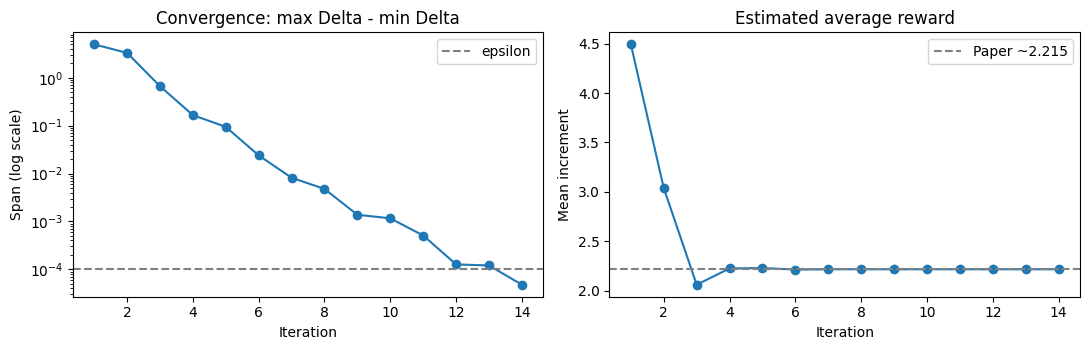

,iteration,span,estimated_gain
6,7,0.008190,2.215181
7,8,0.004770,2.215618
8,9,0.001380,2.214866
9,10,0.001161,2.215086
10,11,0.000508,2.215217
11,12,0.000127,2.215119
12,13,0.000120,2.215140
13,14,0.000048,2.215149


In [15]:
fig, ax = plt.subplots(1,2,figsize=(11,3.6))
iterations = np.arange(1, len(one_m2["spans"])+1)
ax[0].semilogy(iterations, one_m2["spans"], marker="o")
ax[0].axhline(EPSILON, linestyle="--", color="gray", label="epsilon")
ax[0].set(xlabel="Iteration", ylabel="Span (log scale)", title="Convergence: max Delta - min Delta")
ax[0].legend()
ax[1].plot(iterations, one_m2["gains"], marker="o")
ax[1].axhline(2.215, linestyle="--", color="gray", label="Paper ~2.215")
ax[1].set(xlabel="Iteration", ylabel="Mean increment", title="Estimated average reward")
ax[1].legend()
plt.tight_layout(); plt.show()

display(pd.DataFrame({"iteration":iterations, "span":one_m2["spans"],
                      "estimated_gain":one_m2["gains"]}).tail(8))

### Optimal-order heatmap by inventory age

The horizontal axis represents **fresh inventory** and the vertical axis represents **old inventory**. Each cell displays the order quantity selected for that state. Orders are placed today and arrive **tomorrow**. This visualization highlights how optimal replenishment depends on inventory age, not merely total stock.


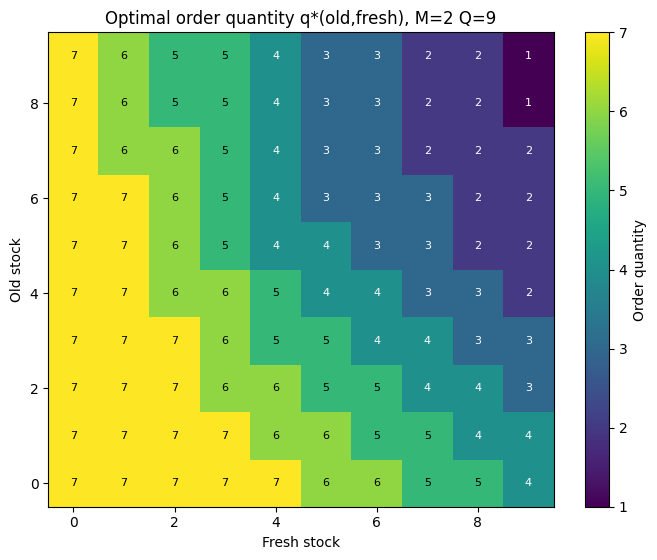

State (0,0) -> 7 ; (9,0) -> 7 ; (0,9) -> 4


In [16]:
Q = one_m2["Q"]
policy_map = one_m2["policy"].reshape(Q+1,Q+1)
fig, ax = plt.subplots(figsize=(7,5.7))
im = ax.imshow(policy_map, origin="lower", cmap="viridis", aspect="auto")
for old in range(Q+1):
    for fresh in range(Q+1):
        ax.text(fresh,old,str(policy_map[old,fresh]),ha="center",va="center",
                fontsize=8,color="white" if policy_map[old,fresh]<5 else "black")
ax.set(xlabel="Fresh stock",ylabel="Old stock", title="Optimal order quantity q*(old,fresh), M=2 Q=9")
fig.colorbar(im,ax=ax,label="Order quantity"); plt.tight_layout();plt.show()
print("State (0,0) ->",policy_map[0,0],"; (9,0) ->",policy_map[9,0],"; (0,9) ->",policy_map[0,9])

## 4. Experiment B — Single product (`M=3, Q=15`) [GPU]

With shelf life `M=3`, the state is `(oldest, middle, freshest)`. The space contains 4,096 states(16^3), updated in parallel using the same CUDA Bellman kernel as Experiment A.

**Reference:** average daily profit approximately **2.4**. Store the result as `one_m3`.


GPU Bellman runtime (excluding table preparation) = 0.021s
VI daily profit = 2.398490
Iterations = 13, final span = 9.703288e-05
Optimal order at zero inventory = 9
Elapsed = 0.08s


/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 32 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


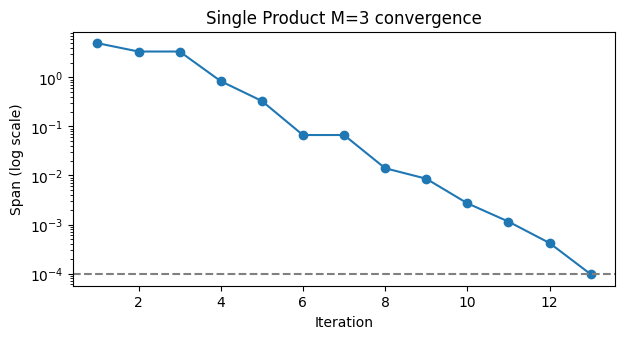

In [17]:
t0 = time.perf_counter()
states, values, policy, spans, gains = solve_single(M=3, Q=15)
one_m3 = dict(M=3, Q=15, states=states, values=values, policy=policy,
              spans=spans, gains=gains)
print(f"VI daily profit = {gains[-1]:.6f}")
print(f"Iterations = {len(spans)}, final span = {spans[-1]:.7g}")
print(f"Optimal order at zero inventory = {policy[0]}")
print(f"Elapsed = {time.perf_counter()-t0:.2f}s")

plt.figure(figsize=(7,3.3))
plt.semilogy(np.arange(1,len(spans)+1),spans,marker="o")
plt.axhline(EPSILON,color="gray",linestyle="--")
plt.xlabel("Iteration");plt.ylabel("Span (log scale)");plt.title("Single Product M=3 convergence")
plt.show()

## 5. Two-product model: one-way substitution from B to A

Let $(D_A,D_B\sim\mathrm{Poisson}(5))$. When demand for product B exceeds available B inventory, each unserved B customer switches to product A independently with probability $(\gamma=0.5)$, subject to A availability.

$
U\mid(D_B-Y_B)^+=x\sim\mathrm{Binomial}(x,\gamma),\qquad
S_A=\min(Y_A,D_A+U),\qquad S_B=\min(Y_B,D_B)
$

`joint[ya, yb, sa, sb]` stores the probability of sales $((s_a,s_b))$ conditional on available inventories $((y_a,y_b))$. The function `joint_sales_prob_fast()` precomputes these probabilities so that value iteration can reuse them efficiently.


In [18]:
def joint_sales_prob_fast(max_a, max_b, mu_a=5., mu_b=5., gamma=.5):

    max_db = int(max(75, poisson.ppf(1-1e-14, mu_b)+5))

    # pb[d] = P(D_B = d), where D_B ~ Poisson(mu_b)
    pb = poisson.pmf(np.arange(max_db+1), mu_b)

    out = np.zeros((max_a+1, max_b+1, max_a+1, max_b+1)) # out[ya,yb,sa,sb] = P(S_A=sa, S_B=sb | Y_A=ya, Y_B=yb)

    for ya in range(max_a+1):

        # pa[sa] = P(min(D_A,ya))
        pa = capped_poisson(mu_a, ya)

        for yb in range(max_b+1):

            # Case 1: D_B < yb (no substitution)
            # P(S_A=sa, S_B=sb) = P(S_A=sa) * P(D_B=sb)
            for sb in range(yb):
                out[ya,yb,:ya+1,sb] = pa * pb[sb]

            # Case 2: D_B >= yb (possible substitution)
            # Excess demand: ex = D_B - yb, U | ex ~ Binomial(ex, gamma)
            pu = np.zeros(max_db-yb+1)

            for db in range(yb,max_db+1):
                ex = db-yb

                # P(U=u) = sum_db P(D_B=db) * P(U=u | ex)
                pu[:ex+1] += (
                    pb[db] * binom.pmf(np.arange(ex+1),ex,gamma)
                )

            # S_A = min(D_A + U, ya), S_B = yb
            for u, p in enumerate(pu):

                if p < 1e-16:
                    continue

                if u >= ya:
                    out[ya, yb, ya, yb] += p
                    continue

                remaining_capacity = ya - u

                p_sa = capped_poisson(mu_a, remaining_capacity)

                # S_A = u + min(D_A, ya-u)
                out[ya, yb, u:ya+1, yb] += p * p_sa

    return out


## 6. Two-product Bellman update on the GPU

The state is `(a_old, a_fresh, b_old, b_fresh)` and the order is `(qa, qb)`. **B → A substitution** is captured by the joint capped-sales probability table `joint[ya,yb,sa,sb]`.

$
V_{k+1}(I)=s_a\mathbb E[S_A\mid I]+s_b\mathbb E[S_B\mid I]
+\max_{q_a,q_b}\left[-c_a q_a-c_b q_b+\sum_{s_a,s_b}p(s_a,s_b\mid I)V_k(F(I,q_a,q_b,s_a,s_b))\right]
$

The GPU update has **two kernels**:

- `two_action_values_gpu`: **one GPU thread per (state, order pair)**; computes the expected future value for that candidate order.
- `two_select_policy_gpu`: **one GPU thread per state**; chooses the best order pair, adds today's expected sales revenue, and computes the Bellman increment.

This retains the CPU baseline's transition logic, probability cutoff (`p < 1e-14`), state ordering. The demand table is created once on the CPU, then copied to the GPU.


### 1) GPU Kernel 1 — Evaluate State-Action Pairs

In [19]:
@cuda.jit
def two_action_values_gpu(joint, W, candidates, Qa, Qb, ca, cb):
    # One GPU thread evaluates one (state, order pair)
    idx = cuda.grid(1)

    # Number of inventory levels and possible orders
    na, nb = Qa + 1, Qb + 1
    actions = na * nb
    states = na * na * nb * nb
    if idx >= states * actions:
        return

    # Decode thread index into state j and order (qa, qb)
    j = idx // actions # state index
    aidx = idx - j * actions # action index
    qa = aidx // nb # order quantity for product A
    qb = aidx % nb # order quantity for product B

    # Decode state j -> (a_old, a_fresh, b_old, b_fresh)
    bf = j % nb # b_fresh
    t = j // nb
    bo = t % nb # b_old
    t = t // nb
    af = t % na # a_fresh
    ao = t // na # a_old

    # Total available inventory of A and B
    ya = ao + af
    yb = bo + bf

    # E[W(I')] = sum_sa sum_sb P(sa,sb|ya,yb) * W(I')
    future = 0.0
    for sa in range(ya + 1):

        # FIFO: remaining fresh A inventory after sales
        ra = af - max(0, sa - ao)
        if ra < 0:
            ra = 0

        for sb in range(yb + 1):
            p = joint[ya, yb, sa, sb]
            if p < 1e-14:
                continue

            # FIFO: remaining fresh B inventory after sales.
            rb = bf - max(0, sb - bo)
            if rb < 0:
                rb = 0

            # Next state = (ra, qa, rb, qb), converted to 1D index
            k = ((ra * na + qa) * nb + rb) * nb + qb

            # Probability-weighted future value
            future += p * W[k]

    # Candidate value = expected future value - ordering costs.
    candidates[idx] = future - ca * qa - cb * qb

### 2) GPU Kernel 2 — Select Optimal Policy

In [20]:
@cuda.jit
def two_select_policy_gpu(candidates, expected_a, expected_b,
                          W, V, policy_a, policy_b, increments,
                          Qa, Qb, price_a, price_b):
    # One GPU thread selects the best order pair for one state
    j = cuda.grid(1)

    na, nb = Qa + 1, Qb + 1
    states = na * na * nb * nb
    if j >= states:
        return

    # Decode state j -> (a_old, a_fresh, b_old, b_fresh)
    bf = j % nb
    t = j // nb
    bo = t % nb
    t = t // nb
    af = t % na
    ao = t // na

    # Total inventory
    ya = ao + af
    yb = bo + bf

    # Find argmax over all (qa, qb)
    best, best_qa, best_qb = -1e100, 0, 0
    base = j * na * nb

    for qa in range(na):
        for qb in range(nb):
            value = candidates[base + qa * nb + qb]
            if value > best:
                best, best_qa, best_qb = value, qa, qb

    # Bellman update: V(I) = expected sales revenue + max(candidate)
    v = price_a * expected_a[ya, yb] + price_b * expected_b[ya, yb] + best

    # Save updated value, Bellman increment, and optimal orders
    V[j] = v
    increments[j] = v - W[j]
    policy_a[j] = best_qa
    policy_b[j] = best_qb


### 3) GPU Solver — Value Iteration

In [21]:
def solve_two_gpu(joint, Qa, Qb, s_a=1., s_b=1., c_a=.5, c_b=.5,
                  epsilon=EPSILON, max_iter=100, threads=128):

    # Precompute E[S_A] and E[S_B] for each inventory pair(depend on current inventory, not today's orders)
    ea = np.zeros((2*Qa+1, 2*Qb+1), dtype=np.float64)
    eb = np.zeros_like(ea)

    for ya in range(2*Qa+1):
        for yb in range(2*Qb+1):
            p = joint[ya, yb, :ya+1, :yb+1]
            ea[ya, yb] = (p * np.arange(ya+1)[:, None]).sum()
            eb[ya, yb] = (p * np.arange(yb+1)[None, :]).sum()

    # Transfer fixed probability and expected-sales tables to GPU
    d_joint = cuda.to_device(np.ascontiguousarray(joint, dtype=np.float64))
    d_ea, d_eb = cuda.to_device(ea), cuda.to_device(eb)

    na, nb = Qa + 1, Qb + 1
    shape = (na, na, nb, nb)
    n_states = na * na * nb * nb
    n_actions = na * nb

    # Initialize GPU arrays for values, candidates, and policies
    d_w = cuda.to_device(np.zeros(n_states, dtype=np.float64))
    d_v = cuda.device_array(n_states, dtype=np.float64)
    d_candidates = cuda.device_array(n_states * n_actions, dtype=np.float64)
    d_pa = cuda.device_array(n_states, dtype=np.int32)
    d_pb = cuda.device_array(n_states, dtype=np.int32)
    d_inc = cuda.device_array(n_states, dtype=np.float64)

    # CUDA configuration: 128 threads per block
    blocks_actions = (n_states * n_actions + threads - 1) // threads
    blocks_states = (n_states + threads - 1) // threads

    spans, gains = [], []

    # Measure GPU Bellman runtime
    cuda.synchronize()
    t0 = time.perf_counter()

    for iteration in range(max_iter):

        # Kernel 1: evaluate every state-action pair in parallel
        two_action_values_gpu[blocks_actions, threads](
            d_joint, d_w, d_candidates, Qa, Qb, c_a, c_b)

        # Kernel 2: select optimal orders and update state values
        two_select_policy_gpu[blocks_states, threads](
            d_candidates, d_ea, d_eb, d_w, d_v, d_pa, d_pb, d_inc,
            Qa, Qb, s_a, s_b)

        # Copy Bellman increments to CPU (synchronizes GPU kernels)
        delta = d_inc.copy_to_host()

        # Span = max(V-W) - min(V-W); gain = mean(V-W)
        span = float(delta.max() - delta.min())
        spans.append(span)
        gains.append(float(delta.mean()))

        # Stop when the span is below the convergence tolerance
        if span < epsilon:
            break

        # Swap previous and updated value arrays for next iteration
        d_w, d_v = d_v, d_w

    cuda.synchronize()
    runtime = time.perf_counter() - t0

    print(f"GPU Bellman runtime (excluding probability preparation) = {runtime:.3f}s")

    # Return value function, optimal policies, and convergence history
    return (d_v.copy_to_host().reshape(shape),
            d_pa.copy_to_host().reshape(shape),
            d_pb.copy_to_host().reshape(shape),
            np.array(spans), np.array(gains))


## 7. Experiment C — Two products (`Qa=Qb=10`) [GPU]

This experiment evaluates **14,641 states**(11^4) and **121 order pairs per state**, with a GPU thread assigned to each state–action combination.

**CPU reference:** profit ≈ **4.503204**, 13 iterations, zero-stock order `(8, 7)` (as observed in the prior CPU run). The published **5.509** figure is not matched by the CPU implementation; do not treat that number as a GPU target until the discrepancy is resolved.

**Performance note:** GPU kernel compilation and host↔device transfers affect wall time. Compare steady-state GPU and CPU times only under matched conditions and with compilation excluded.


In [22]:
QA = QB = 10
t0 = time.perf_counter()
joint = joint_sales_prob_fast(2*QA, 2*QB, MU_A, MU_B, GAMMA)
V2, pa2, pb2, spans2, gains2 = solve_two_gpu(
    joint, QA, QB, PRICE_A, PRICE_B, COST_A, COST_B, EPSILON, 100)
two_result = dict(Qa=QA, Qb=QB, values=V2, policy_a=pa2, policy_b=pb2,
                  spans=spans2, gains=gains2)
print(f"GPU VI daily profit = {gains2[-1]:.6f} (CPU reference ~4.503204)")
print(f"Iterations = {len(spans2)}, final span = {spans2[-1]:.7g}")
print("Optimal order at zero inventory =", (int(pa2[0,0,0,0]), int(pb2[0,0,0,0])))
print(f"Wall time (including preparation/compilation) = {time.perf_counter()-t0:.2f}s")


/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 115 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


GPU Bellman runtime (excluding probability preparation) = 1.466s
GPU VI daily profit = 4.503204 (CPU reference ~4.503204)
Iterations = 13, final span = 7.101798e-05
Optimal order at zero inventory = (8, 7)
Wall time (including preparation/compilation) = 15.26s


### Results

- **Paper:** Average daily profit ≈ **5.509**
- **CPU implementation:** Average daily profit ≈ **4.503204**
- **GPU implementation:** Average daily profit ≈ **4.503204**
- **Convergence:** 13 iterations, final span ≈ $(7.1 \times 10^{-5})$
- **Optimal order at zero inventory:** (8, 7)

### Interpretation

The reproduced average daily profit of **4.503204** differs from the **5.509** reported in the paper. However, the CPU and GPU implementations produce the same result, suggesting that the GPU parallelization preserves the numerical results of the CPU model.

The discrepancy with the paper remains unresolved and may be related to differences in the model formulation, probability calculations, or reported results. Further verification is needed before claiming full reproduction of the published results.

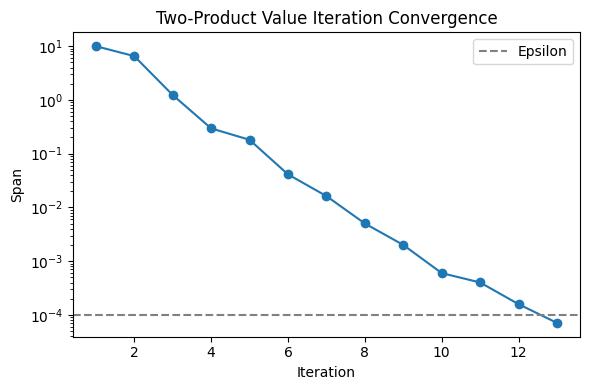

In [23]:
fig, ax = plt.subplots(figsize=(6, 4))

it = np.arange(1, len(two_result["spans"]) + 1)

ax.semilogy(it, two_result["spans"], marker="o")
ax.axhline(EPSILON, linestyle="--", color="gray", label="Epsilon")
ax.set(
    xlabel="Iteration",
    ylabel="Span",
    title="Two-Product Value Iteration Convergence"
)

ax.legend()
plt.tight_layout()
plt.show()



## 8. Runtime Comparison using different thread block sizes

This experiment compares the total execution time of the two-product GPU Value Iteration using different CUDA thread block sizes.

### Configuration

- **States:** 14,641
- **Actions per state:** 121
- **Threads per block:** 64, 128, 256, 512
- **Convergence tolerance:** 1e-4
- **Repeated runs:** 5 per configuration

### Performance Measurement

- Each run starts with a zero-initialized value function.
- Both GPU kernels are executed repeatedly until the span is below the convergence tolerance.
- A warm-up run excludes CUDA JIT compilation overhead.
- Runtime includes solver initialization, GPU computation, synchronization, and data transfers.
- Final profit and iteration count are recorded to verify consistency.

### Interpretation

The configuration with the lowest average runtime provides the best measured performance for the complete GPU solver.

Comparing the results with the single-update benchmark helps determine whether improvements in kernel execution time translate into faster overall Value Iteration.

In [24]:
import time
import numpy as np
import pandas as pd

def benchmark_full_vi(joint, Qa=10, Qb=10, repeats=5):
    results = []

    for threads in [64, 128, 256, 512]:

        # Warm-up: exclude CUDA JIT compilation
        solve_two_gpu(joint, Qa, Qb, threads=threads)

        times = []
        iterations = []
        profits = []

        for _ in range(repeats):
            cuda.synchronize()
            start = time.perf_counter()

            V, pa, pb, spans, gains = solve_two_gpu(
                joint, Qa, Qb, threads=threads
            )

            cuda.synchronize()
            elapsed = time.perf_counter() - start

            times.append(elapsed)
            iterations.append(len(spans))
            profits.append(gains[-1])

        results.append({
            "Threads/Block": threads,
            "Iterations": iterations[0],
            "Mean Time (s)": np.mean(times),
            "Std (s)": np.std(times),
            "Min Time (s)": np.min(times),
            "Final Profit": np.mean(profits),
            "Converged": bool(spans[-1] < EPSILON)
        })

    df = pd.DataFrame(results)

    baseline = df.loc[
        df["Threads/Block"] == 128, "Mean Time (s)"
    ].iloc[0]

    df["Speedup vs 128"] = baseline / df["Mean Time (s)"]

    return df.round(4)


# Full Value Iteration benchmark
vi_results = benchmark_full_vi(joint, Qa=10, Qb=10)
display(vi_results)


GPU Bellman runtime (excluding probability preparation) = 0.159s
GPU Bellman runtime (excluding probability preparation) = 0.138s
GPU Bellman runtime (excluding probability preparation) = 0.078s
GPU Bellman runtime (excluding probability preparation) = 0.076s
GPU Bellman runtime (excluding probability preparation) = 0.068s
GPU Bellman runtime (excluding probability preparation) = 0.069s
GPU Bellman runtime (excluding probability preparation) = 0.068s
GPU Bellman runtime (excluding probability preparation) = 0.069s
GPU Bellman runtime (excluding probability preparation) = 0.077s
GPU Bellman runtime (excluding probability preparation) = 0.071s
GPU Bellman runtime (excluding probability preparation) = 0.068s
GPU Bellman runtime (excluding probability preparation) = 0.069s
GPU Bellman runtime (excluding probability preparation) = 0.094s


/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 58 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


GPU Bellman runtime (excluding probability preparation) = 0.072s
GPU Bellman runtime (excluding probability preparation) = 0.068s
GPU Bellman runtime (excluding probability preparation) = 0.068s
GPU Bellman runtime (excluding probability preparation) = 0.068s
GPU Bellman runtime (excluding probability preparation) = 0.068s
GPU Bellman runtime (excluding probability preparation) = 0.068s


/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 29 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


GPU Bellman runtime (excluding probability preparation) = 0.068s
GPU Bellman runtime (excluding probability preparation) = 0.069s
GPU Bellman runtime (excluding probability preparation) = 0.070s
GPU Bellman runtime (excluding probability preparation) = 0.070s
GPU Bellman runtime (excluding probability preparation) = 0.069s


,Threads/Block,Iterations,Mean Time (s),Std (s),Min Time (s),Final Profit,Converged,Speedup vs 128
0,64,13,0.1015,0.0262,0.0839,4.5032,True,0.8768
1,128,13,0.0890,0.0067,0.0835,4.5032,True,1.0000
2,256,13,0.0906,0.0175,0.0764,4.5032,True,0.9827
3,512,13,0.0813,0.0034,0.0771,4.5032,True,1.0947


### Results and Interpretation

All four configurations converged after 13 iterations, producing the same average daily profit of approximately 4.5032.

- **64 threads:** 83.3 ms
- **128 threads:** 80.7 ms
- **256 threads:** 81.6 ms
- **512 threads:** 80.6 ms

Tull Value Iteration benchmark showed almost no performance difference across configurations.

This suggests that improvements in individual kernel execution time do not necessarily translate into equivalent improvements in total solver runtime, where memory transfers, synchronization, and convergence checks also contribute.

**Conclusion:** Thread block size had little impact on the measured full Value Iteration runtime, while all configurations produced consistent numerical results.

## 9. Monte Carlo policy evaluation (CPU)

Value iteration runs on the GPU and analytically sums demand probabilities. Simulation draws **random daily Poisson/Binomial demand** and evolves inventory **one day at a time**.

The simulation runs for **400,000 days** by default. It remains on the CPU because inventory updates are sequential in time. The GPU-generated optimal policies (`one_m2`, `two_result`) are copied back to the CPU and can be evaluated without changing the original simulation functions.


### 1) Single-Product Simulation

In [25]:
def simulate_one(policy, M, Q, mu=5., s=1., c=.5, periods=400_000, seed=123):
    # Initialize random demand, inventory, and performance records
    rng = np.random.default_rng(seed)
    I = [0] * M
    profits = np.empty(periods)
    waste = orders = 0
    demand = rng.poisson(mu, size=periods)
    running = np.empty(periods // 1000)

    for t, d in enumerate(demand):

        # Convert inventory state I into a 1D index
        j = 0
        for x in I:
            j = j * (Q+1) + x

        # Select the optimal order from the VI policy
        q = int(policy[j])

        # Sales
        sales = min(sum(I), int(d))

        # Daily profit
        profits[t] = s*sales - c*q

        # Expired oldest inventory and total ordered units
        waste += max(0, I[0]-d)
        orders += q

        # FIFO
        remaining = int(d)
        for r in range(M):
            take = min(I[r], remaining)
            I[r] -= take
            remaining -= take

        # Age inventory and receive today's order tomorrow
        I = I[1:] + [q]

        # Record cumulative average profit every 1,000 days
        if (t+1) % 1000 == 0:
            running[t // 1000] = profits[:t+1].mean()

    # Return average daily profit, waste ratio, and profit history
    return dict(profit=float(profits.mean()),
                waste_pct=100*waste/orders,
                running_profit=running)


### 2) Two-Product Simulation

In [26]:
def simulate_two(result, periods=400_000, seed=123, mu_a=5., mu_b=5.,
                 gamma=.5, s_a=1., s_b=1., c_a=.5, c_b=.5):

    # Initialize random generator and optimal policies
    rng = np.random.default_rng(seed)
    pa, pb = result['policy_a'], result['policy_b']

    # State = (A old, A fresh, B old, B fresh)
    ao=af=bo=bf=0
    sum_profit=0.
    waste_a=waste_b=orders_a=orders_b=0
    running = np.empty(periods // 1000)

    for t in range(periods):

        # Select optimal orders from the VI policies
        qa=int(pa[ao,af,bo,bf]) # optimal order for A
        qb=int(pb[ao,af,bo,bf]) # optimal order for B

        # Independent Poisson demand for A and B
        da=rng.poisson(mu_a)
        db=rng.poisson(mu_b)

        # B -> A substitution: U ~ Binomial(max(0, D_B-Y_B), gamma)
        sub=rng.binomial(max(0, db-bo-bf), gamma)

        # S_A = min(Y_A, D_A+U); S_B = min(Y_B, D_B)
        sold_a=min(ao+af, da+sub)
        sold_b=min(bo+bf, db)

        # Daily profit
        sum_profit += s_a*sold_a+s_b*sold_b-c_a*qa-c_b*qb

        # Expired oldest inventory and accumulated orders
        waste_a += max(0, ao-sold_a)
        waste_b += max(0, bo-sold_b)
        orders_a += qa
        orders_b += qb

        # FIFO
        af=max(0, af-max(0, sold_a-ao))
        bf=max(0, bf-max(0, sold_b-bo))

        # Next state = (remaining A, new A order, remaining B, new B order)
        ao,af,bo,bf=af,qa,bf,qb

        # Record cumulative average profit every 1,000 days
        if (t+1) % 1000 == 0:
            running[t // 1000] = sum_profit/(t+1)

    # Return average profit, waste ratios, and profit history
    return dict(profit=sum_profit/periods,
                waste_a_pct=100*waste_a/orders_a,
                waste_b_pct=100*waste_b/orders_b,
                running_profit=running)


### 3) Base-Stock Simulation

In [27]:
def simulate_base_stock_two(Sa=13, Sb=12, periods=400_000, seed=123,
                            mu_a=5., mu_b=5., gamma=.5,
                            s_a=1., s_b=1., c_a=.5, c_b=.5):

    # Initialize random generator, inventory, and performance records
    rng=np.random.default_rng(seed)
    ao=af=bo=bf=0
    profit=0.
    waste_a=waste_b=orders_a=orders_b=0
    running = np.empty(periods // 1000)

    for t in range(periods):

        # Base-stock orders with expected waste adjustment
        # q = max(0, S - total_inventory + max(0, old_inventory-mu))
        qa=max(0, Sa-ao-af+max(0,ao-mu_a))
        qb=max(0, Sb-bo-bf+max(0,bo-mu_b))

        # Generate independent Poisson demand
        da=rng.poisson(mu_a)
        db=rng.poisson(mu_b)

        # B -> A substitution for unmet B demand
        sub=rng.binomial(max(0,db-bo-bf),gamma)

        # Actual sales limited by available inventory
        sa=min(ao+af,da+sub)
        sb=min(bo+bf,db)

        # Daily profit
        profit += s_a*sa+s_b*sb-c_a*qa-c_b*qb

        # Record expired inventory and ordered quantities
        waste_a += max(0,ao-sa)
        waste_b += max(0,bo-sb)
        orders_a += qa
        orders_b += qb

        # FIFO
        next_ao=max(0,af-max(0,sa-ao))
        next_bo=max(0,bf-max(0,sb-bo))

        # Update next-day inventory with incoming orders
        ao,af,bo,bf=next_ao,qa,next_bo,qb

        # Record cumulative average profit every 1,000 days
        if (t+1) % 1000 == 0:
            running[t // 1000] = profit/(t+1)

    # Return average profit, waste ratios, and profit history
    return dict(profit=profit/periods,
                waste_a_pct=100*waste_a/orders_a,
                waste_b_pct=100*waste_b/orders_b,
                running_profit=running)


## Policy Simulation and Validation

### 1. Single-Product VI Policy

The single-product simulation applies the optimal ordering policy obtained from Value Iteration.

- **Ordering:** `q = policy[I]`
- **Demand:** Poisson distribution with mean μ = 5
- **Sales:** `min(D, Y)`
- **Inventory update:** FIFO with a one-day ordering lead time

The simulated average daily profit is compared with the VI estimate (**2.215149**) to validate the policy.

### 2. Two-Product VI Policy

The two-product simulation applies the optimal ordering policies for products A and B, including one-way substitution from B to A.

- **Ordering:** `(qa, qb) = (policy_a[I], policy_b[I])`
- **Demand:** Independent Poisson distributions with means μA = μB = 5
- **Substitution:** `U ~ Binomial(max(0, DB - YB), γ)`
- **Sales:** `SA = min(DA + U, YA)`, `SB = min(DB, YB)`
- **Inventory update:** FIFO for both products

The simulated average daily profit is compared with the VI estimate (**4.503204**) to validate the two-product policy.

### 3. Two-Product Base-Stock Policy

The base-stock simulation uses a fixed inventory target instead of the optimal policy obtained from Value Iteration.

- **Target levels:** Sa = 13, Sb = 12
- **Ordering:** `q = max(0, S - Y + max(0, I_old - μ))`
- **Demand and substitution:** Same as the two-product VI simulation
- **Inventory update:** FIFO for both products

This serves as a baseline for evaluating the improvement achieved by the VI policy.

### Performance Measures

All three simulations report:

- **Average daily profit:** Sales revenue minus ordering costs, averaged over 400,000 days
- **Waste percentage:** Expired inventory divided by total ordered units
- **Running average profit:** Cumulative average profit recorded every 1,000 days


### 1) Single-product policy simulation

,Method,Daily Profit,Waste (%)
0,Value Iteration,2.2151,NaN
1,VI Policy (Simulation),2.2149,5.7702


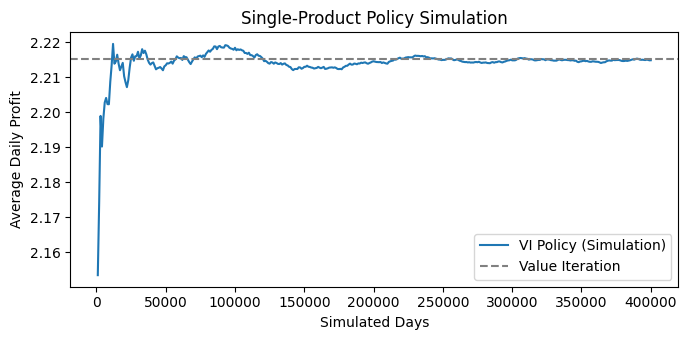

In [28]:
one_sim = simulate_one(
    one_m2["policy"], M=2, Q=9,
    periods=400_000, seed=SEED
)

# Summary table
single_summary = pd.DataFrame([
    {
        "Method": "Value Iteration",
        "Daily Profit": one_m2["gains"][-1],
        "Waste (%)": np.nan
    },
    {
        "Method": "VI Policy (Simulation)",
        "Daily Profit": one_sim["profit"],
        "Waste (%)": one_sim["waste_pct"]
    }
])

display(single_summary.round(4))

# Running average profit vs VI estimate
days = np.arange(1, len(one_sim["running_profit"]) + 1) * 1000

plt.figure(figsize=(7, 3.5))
plt.plot(days, one_sim["running_profit"], label="VI Policy (Simulation)")
plt.axhline(
    one_m2["gains"][-1],
    linestyle="--", color="gray",
    label="Value Iteration"
)

plt.xlabel("Simulated Days")
plt.ylabel("Average Daily Profit")
plt.title("Single-Product Policy Simulation")
plt.legend()
plt.tight_layout()
plt.show()


### 2) Two-product policy simulation

,Method,Daily Profit,Waste A (%),Waste B (%)
0,Value Iteration,4.5032,NaN,NaN
1,VI Policy (Simulation),4.5007,6.0310,4.1947
2,Base-Stock (Simulation),4.4691,6.3241,5.3220


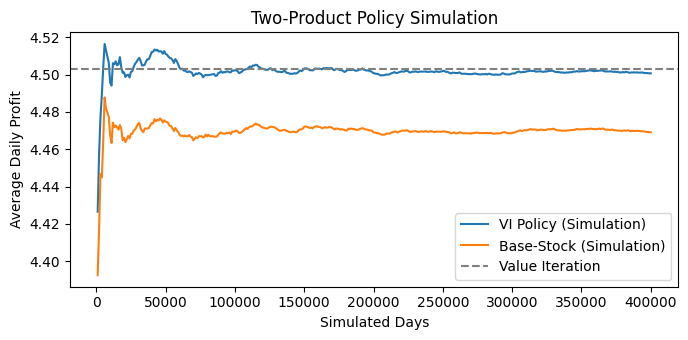

In [29]:
vi_sim = simulate_two(
    two_result, periods=400_000, seed=SEED,
    mu_a=MU_A, mu_b=MU_B, gamma=GAMMA,
    s_a=PRICE_A, s_b=PRICE_B,
    c_a=COST_A, c_b=COST_B
)

base_sim = simulate_base_stock_two(
    periods=400_000, seed=SEED,
    mu_a=MU_A, mu_b=MU_B, gamma=GAMMA,
    s_a=PRICE_A, s_b=PRICE_B,
    c_a=COST_A, c_b=COST_B
)

# Summary table
two_summary = pd.DataFrame([
    {
        "Method": "Value Iteration",
        "Daily Profit": two_result["gains"][-1],
        "Waste A (%)": np.nan,
        "Waste B (%)": np.nan
    },
    {
        "Method": "VI Policy (Simulation)",
        "Daily Profit": vi_sim["profit"],
        "Waste A (%)": vi_sim["waste_a_pct"],
        "Waste B (%)": vi_sim["waste_b_pct"]
    },
    {
        "Method": "Base-Stock (Simulation)",
        "Daily Profit": base_sim["profit"],
        "Waste A (%)": base_sim["waste_a_pct"],
        "Waste B (%)": base_sim["waste_b_pct"]
    }
])

display(two_summary.round(4))

# Running average profit vs VI estimate
days = np.arange(1, len(vi_sim["running_profit"]) + 1) * 1000

plt.figure(figsize=(7, 3.5))
plt.plot(days, vi_sim["running_profit"], label="VI Policy (Simulation)")
plt.plot(days, base_sim["running_profit"], label="Base-Stock (Simulation)")
plt.axhline(
    two_result["gains"][-1],
    linestyle="--", color="gray",
    label="Value Iteration"
)

plt.xlabel("Simulated Days")
plt.ylabel("Average Daily Profit")
plt.title("Two-Product Policy Simulation")
plt.legend()
plt.tight_layout()
plt.show()


### 3) Base-Stock Policy Simulation

,Method,Daily Profit,Waste A (%),Waste B (%)
0,Base-Stock (Simulation),4.4691,6.3241,5.322


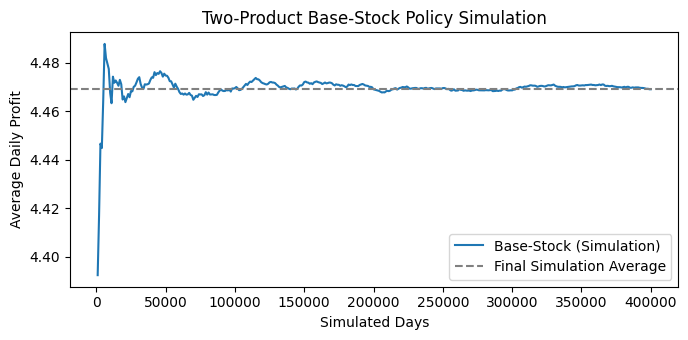

In [30]:
base_sim = simulate_base_stock_two(
    Sa=13, Sb=12,
    periods=400_000, seed=SEED,
    mu_a=MU_A, mu_b=MU_B, gamma=GAMMA,
    s_a=PRICE_A, s_b=PRICE_B,
    c_a=COST_A, c_b=COST_B
)

# Summary table
base_summary = pd.DataFrame([
    {
        "Method": "Base-Stock (Simulation)",
        "Daily Profit": base_sim["profit"],
        "Waste A (%)": base_sim["waste_a_pct"],
        "Waste B (%)": base_sim["waste_b_pct"]
    }
])

display(base_summary.round(4))

# Running average daily profit
days = np.arange(1, len(base_sim["running_profit"]) + 1) * 1000

plt.figure(figsize=(7, 3.5))
plt.plot(
    days, base_sim["running_profit"],
    label="Base-Stock (Simulation)"
)

plt.axhline(
    base_sim["profit"],
    linestyle="--", color="gray",
    label="Final Simulation Average"
)

plt.xlabel("Simulated Days")
plt.ylabel("Average Daily Profit")
plt.title("Two-Product Base-Stock Policy Simulation")
plt.legend()
plt.tight_layout()
plt.show()

### Results and Interpretation

| Method | Average Daily Profit |
|---|---:|
| Single-Product VI (Model) | 2.215149 |
| Two-Product VI (Model) | 4.503204 |
| Two-Product VI (Simulation) | 4.500659 |
| Two-Product Base-Stock (Simulation) | 4.469071 |

The simulation results are consistent with the VI estimates. In the two-product experiment, the VI policy achieves slightly higher average profit and lower waste rates than the base-stock policy.

The running average profit graphs illustrate how the simulated average profit stabilizes over time.

**Note:** Single-product and two-product profits are not directly comparable because they represent different inventory systems. The relevant policy comparison is between two-product VI and two-product base-stock.


## 10. Important limitations
- CUDA requires a compatible NVIDIA GPU; **Apple Silicon does not execute NVIDIA CUDA kernels**.
- Running on GPU does not guarantee a speedup for small state spaces; kernel launch overhead and memory access matter.
- The two-product code uses a thread per **state–action pair**, rather than the paper's exact GPU block/thread mapping per order/event. The Bellman model is retained, but benchmark speedups are **not directly comparable** with the original 2019 hardware results.
- The `numba` CUDA simulator can test small cases, but its runtimes are **not GPU benchmarks**.


## 11. CPU vs GPU — Value Iteration Benchmark

This section compares the performance of CPU and GPU implementations of the same Value Iteration algorithm without modifying the original code.

Both implementations use the same model parameters, probability distributions, Bellman equation, and convergence criteria.

### Benchmark Steps

1. **Probability Preparation:** Compute the joint sales probabilities used by both CPU and GPU.
2. **JIT Warm-up:** Run a small example to compile the functions before measuring execution time.
3. **CPU Execution:** Run Value Iteration sequentially on the CPU and measure its execution time.
4. **GPU Execution:** Run the existing CUDA implementation and measure computation and data transfer times.
5. **Result Comparison:** Check whether CPU and GPU produce the same optimal policy, daily profit, and number of iterations.
6. **Speedup:** Compare CPU and GPU execution times.

### Performance Measurement

- **Bellman Computation:** Time spent running Value Iteration, including convergence checks.
- **Solver Total:** Computation time plus GPU setup and data transfer.
- **End-to-End:** Total time including probability preparation.

Speedup is calculated as:

$[
\text{Speedup}=\frac{\text{CPU Time}}{\text{GPU Time}}
]$

A speedup greater than 1 means the GPU is faster.

The GPU implementation uses state-action parallelization, which differs from the paper's demand-event parallelization.

In [33]:
from numba import njit

@njit
def two_vi_cpu_sequential(joint, ea, eb, Qa, Qb, s_a, s_b, c_a, c_b,
                          epsilon, max_iter):
    """Run two-product Value Iteration sequentially on the CPU."""

    # 1. Define the state space
    na, nb = Qa + 1, Qb + 1
    n_states = na * na * nb * nb

    # Value functions: W = previous iteration, V = new iteration
    W = np.zeros(n_states, dtype=np.float64)
    V = np.empty_like(W)

    # Optimal ordering policies for products A and B
    pa = np.empty(n_states, dtype=np.int32)
    pb = np.empty(n_states, dtype=np.int32)

    # Store convergence information
    spans = np.empty(max_iter, dtype=np.float64)
    gains = np.empty(max_iter, dtype=np.float64)

    # 2. Value Iteration
    for it in range(max_iter):
        dmin, dmax, dsum = 1e300, -1e300, 0.0

        # Evaluate every inventory state
        for j in range(n_states):

            # Convert flat state index into (A_old, A_fresh, B_old, B_fresh)
            bf = j % nb
            t = j // nb
            bo = t % nb
            t //= nb
            af = t % na
            ao = t // na

            # Total inventory
            ya, yb = ao + af, bo + bf

            # Initialize
            best, best_a, best_b = -1e300, 0, 0

            # 3. Evaluate all possible ordering decisions
            for qa in range(na):
                for qb in range(nb):
                    future = 0.0

                    # 4. Evaluate all possible sales outcomes
                    for sa in range(ya + 1):

                        # Remaining fresh inventory A after FIFO sales
                        ra = max(0, af - max(0, sa - ao))

                        for sb in range(yb + 1):

                            # Probability of selling (sa, sb)
                            p = joint[ya, yb, sa, sb]

                            if p < 1e-14:
                                continue

                            # Remaining fresh inventory B after FIFO sales
                            rb = max(0, bf - max(0, sb - bo))

                            # Next state: (remaining A, new A, remaining B, new B)
                            k = ((ra * na + qa) * nb + rb) * nb + qb

                            # Expected future value
                            future += p * W[k]

                    # Bellman action value: future value - ordering cost
                    candidate = future - c_a * qa - c_b * qb

                    # Keep the best ordering decision
                    if candidate > best:
                        best, best_a, best_b = candidate, qa, qb

            # 5. Update the value function
            # Immediate expected revenue + best future value
            v = s_a * ea[ya, yb] + s_b * eb[ya, yb] + best

            V[j] = v
            pa[j], pb[j] = best_a, best_b

            # Change in value function for this state
            delta = v - W[j]

            if delta < dmin:
                dmin = delta
            if delta > dmax:
                dmax = delta

            dsum += delta

        # 6. Check convergence
        span = dmax - dmin
        spans[it] = span
        gains[it] = dsum / n_states

        if span < epsilon:
            return (
                V.reshape(na, na, nb, nb),
                pa.reshape(na, na, nb, nb),
                pb.reshape(na, na, nb, nb),
                spans[:it+1],
                gains[:it+1]
            )

        # Use the new values in the next iteration
        W, V = V, W

    return (
        V.reshape(na, na, nb, nb),
        pa.reshape(na, na, nb, nb),
        pb.reshape(na, na, nb, nb),
        spans,
        gains
    )

### 11.1 Warm-up, Benchmark, and CPU–GPU Validation

This section compares the execution time and results of CPU and GPU Value Iteration.

**1. JIT Warm-up**

First run a small problem to compile the CPU and GPU functions.

This warm-up time is excluded from the benchmark so that compile time is excluded.

**2. Repeated GPU Runs**


**median execution time** to reduce the effect of unusually slow or fast runs. The CPU solver is run once by default because it takes longer.

**3. CPU–GPU Validation**

Both CPU and GPU use the same parameters, probability tables, initial values, and convergence criteria.

The following results should be same:

- Number of iterations
- Average daily profit
- Value Function
- Optimal ordering policy

**4. GPU Execution Time**

GPU execution includes both computation and data transfers.

- **H2D (Host-to-Device):** Copy data from CPU memory to GPU memory.
- **Kernel Execution:** Perform Value Iteration calculations on the GPU.
- **D2H (Device-to-Host):** Copy results from GPU memory back to CPU memory.

The measured `Kernel completion + increment D2H` time includes waiting for GPU calculations to finish, not just data transfer.

In [32]:
BENCH_QA = 10
BENCH_QB = 10
GPU_REPEATS = 3
BENCH_THREADS = 128

# 1. JIT warm-up on a small problem (excluded from the timed benchmark)
t = time.perf_counter()
small_joint = joint_sales_prob_fast(4, 4, MU_A, MU_B, GAMMA)
small_ea, small_eb = expected_sales_tables(small_joint, 2, 2)
cpu_small = two_vi_cpu_sequential(small_joint, small_ea, small_eb, 2, 2,
                                  PRICE_A, PRICE_B, COST_A, COST_B, EPSILON, 100)
cpu_warmup = time.perf_counter()-t

t = time.perf_counter()
gpu_small, _ = run_gpu_profiled(small_joint, small_ea, small_eb, 2, 2,
                                epsilon=EPSILON, threads=BENCH_THREADS)
gpu_warmup = time.perf_counter()-t

# 2. One shared probability table (same inputs for both solvers)
t = time.perf_counter()
bench_joint = joint_sales_prob_fast(2*BENCH_QA, 2*BENCH_QB, MU_A, MU_B, GAMMA)
bench_ea, bench_eb = expected_sales_tables(bench_joint, BENCH_QA, BENCH_QB)
prob_prep = time.perf_counter()-t

# 3. Sequential CPU, already JIT-compiled
t = time.perf_counter()
cpu_result = two_vi_cpu_sequential(
    bench_joint, bench_ea, bench_eb, BENCH_QA, BENCH_QB,
    PRICE_A, PRICE_B, COST_A, COST_B, EPSILON, 100)
cpu_bellman = time.perf_counter()-t

# 4. GPU, already JIT-compiled; report median warm-runtime
gpu_runs = []
for _ in range(GPU_REPEATS):
    result, timing = run_gpu_profiled(
        bench_joint, bench_ea, bench_eb, BENCH_QA, BENCH_QB,
        epsilon=EPSILON, max_iter=100, threads=BENCH_THREADS)
    gpu_runs.append((result, timing))
gpu_result, gpu_times = min(
    gpu_runs, key=lambda x: abs(x[1]['GPU solver total (s)'] -
                                np.median([z[1]['GPU solver total (s)'] for z in gpu_runs])))

# 5. Exact policy comparison and numerical consistency
cv, cpa, cpb, cspans, cgains = cpu_result
gv, gpa, gpb, gspans, ggains = gpu_result
max_v_err = float(np.max(np.abs(cv - gv)))
policy_equal = bool(np.array_equal(cpa,gpa) and np.array_equal(cpb,gpb))
iterations_equal = len(cspans) == len(gspans)
profit_err = abs(float(cgains[-1]) - float(ggains[-1]))

print('JIT warm-up (tiny instance, compilation + execution):',
      f'CPU {cpu_warmup:.3f}s / GPU {gpu_warmup:.3f}s')
print('State count:', (BENCH_QA+1)**2*(BENCH_QB+1)**2)
print('CPU / GPU iterations:', len(cspans), '/', len(gspans))
print('CPU / GPU daily profit:', round(float(cgains[-1]),7), '/', round(float(ggains[-1]),7))
print('Max absolute value-function difference:', max_v_err)
print('Policy exactly equal:', policy_equal)
print('Profit difference:', profit_err)

if not iterations_equal or not np.allclose(cv,gv,atol=1e-6,rtol=1e-8) or profit_err>1e-6:
    raise AssertionError('CPU and GPU Bellman solutions differ; do not interpret speedup yet.')
# Optimal actions may differ at numerical ties; flag, but do not automatically fail.
if not policy_equal:
    print('WARNING: Policy mismatch. Check tie-breaking and near-ties.')

cpu_total = prob_prep + cpu_bellman
gpu_total = prob_prep + gpu_times['GPU solver total (s)']
summary = pd.DataFrame([
    {'Metric':'Probability preparation (shared)','CPU (s)':prob_prep,'GPU (s)':prob_prep},
    {'Metric':'Setup + host-to-device','CPU (s)':0.0,'GPU (s)':gpu_times['GPU setup + H2D (s)']},
    {'Metric':'Bellman loop + convergence','CPU (s)':cpu_bellman,'GPU (s)':gpu_times['GPU Bellman + convergence (s)']},
    {'Metric':'Final device-to-host','CPU (s)':0.0,'GPU (s)':gpu_times['GPU final D2H (s)']},
    {'Metric':'Solver total, excluding probability prep','CPU (s)':cpu_bellman,'GPU (s)':gpu_times['GPU solver total (s)']},
    {'Metric':'End-to-end, including probability prep','CPU (s)':cpu_total,'GPU (s)':gpu_total},
])
display(summary.round(5))

speedup = pd.DataFrame([
    {'Measure':'Bellman compute speedup','CPU / GPU':cpu_bellman/gpu_times['GPU Bellman + convergence (s)']},
    {'Measure':'Solver speedup (includes H2D and final D2H)','CPU / GPU':cpu_bellman/gpu_times['GPU solver total (s)']},
    {'Measure':'End-to-end speedup (includes probability prep)','CPU / GPU':cpu_total/gpu_total},
])
display(speedup.round(3))
print('GPU repeat solver times (s):', [round(x[1]['GPU solver total (s)'],4) for x in gpu_runs])
print('GPU host-observed kernel+increment-copy time (s):',
      round(gpu_times['Kernel completion + increment D2H (s)'],4))


/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 6 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 1 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


JIT warm-up (tiny instance, compilation + execution): CPU 2.069s / GPU 0.007s
State count: 14641
CPU / GPU iterations: 13 / 13
CPU / GPU daily profit: 4.5032044 / 4.5032044
Max absolute value-function difference: 5.684341886080802e-14
Policy exactly equal: True
Profit difference: 2.042810365310288e-14


,Metric,CPU (s),GPU (s)
0,Probability preparation (shared),4.88294,4.88294
1,Setup + host-to-device,0.00000,0.00239
2,Bellman loop + convergence,8.24142,0.11127
3,Final device-to-host,0.00000,0.00023
4,"Solver total, excluding probability prep",8.24142,0.11389
5,"End-to-end, including probability prep",13.12437,4.99684


,Measure,CPU / GPU
0,Bellman compute speedup,74.064
1,Solver speedup (includes H2D and final D2H),72.360
2,End-to-end speedup (includes probability prep),2.627


GPU repeat solver times (s): [0.1496, 0.1139, 0.0925]
GPU host-observed kernel+increment-copy time (s): 0.1067


### 11.2 Interpretation

**1. CPU–GPU Validation**

Both CPU and GPU produced the same results for iterations, daily profit, value finction, optimal policy. This confirms that GPU parallelization produces the same numerical results as sequential CPU Value Iteration.

**2. Execution Time**

| Measurement | CPU | GPU | Speedup |
|---|---:|---:|---:|
| Bellman Loop | 8.2414 s | 0.1113 s | 74.06× |
| Solver Total | 8.2414 s | 0.1139 s | 72.36× |
| End-to-End | 13.1244 s | 4.9968 s | 2.63× |

- **Bellman Loop:** GPU is approximately 74 times faster in Value Iteration computation.
- **Solver Total:** Including GPU setup and data transfers, GPU is approximately 72 times faster.
- **End-to-End:** Including probability preparation (4.88 s), the overall speedup decreases to 2.63×.

Probability preparation takes the same amount of time for both implementations because it is performed on the CPU.

**3. Repeated GPU Runs**

The GPU solver was executed three times with the same initial conditions.

- Run 1: 0.1496 s
- Run 2: 0.1139 s
- Run 3: 0.0925 s

The median time, **0.1139 s**, is used for the speedup calculation to reduce the effect of runtime variation.

Each run solves the entire Value Iteration problem from initialization to convergence.

**4. GPU Timing Details**

- **JIT Warm-up:** Compiles the functions before benchmarking. Compilation time is excluded.
- **Setup + H2D (0.00239 s):** Allocates GPU memory and transfers input data.
- **Kernel Completion + Increment D2H (0.1067 s):** Includes GPU computation completion and transferring convergence data to the CPU.
- **Final D2H (0.00023 s):** Transfers the final Value Function and policies to the CPU.

**5. Comparison with the Original Paper**

The original paper reported a maximum speedup of **11.7×** using C/CUDA on an NVIDIA K80.

The State–Action GPU implementation achieved a **72.36× solver speedup** on a Tesla T4.

However, these results are not directly comparable because of differences in hardware, programming methods, and benchmark conditions.

- **Original paper:** Demand-event parallelization with 100 fixed iterations for timing.
- **Current implementation:** State–Action parallelization with convergence at `span < 1e-4`.

**Conclusion**

- CPU and GPU produce identical optimal ordering policies and average daily profits.
- State–Action GPU parallelization reduces solver time from **8.24 s to 0.114 s (72.36× speedup)**.
- Probability preparation remains a major part of the total runtime, reducing the end-to-end speedup to **2.63×**.

### 12. Original Approach — Demand-event Parallelization

To compare the GPU parallelization methods, an additional CUDA implementation is introduced based on the **Demand-event Parallelization** approach used in Ortega et al. (2019).

The original paper and the existing implementation use different parallelization strategies:

- **Original Paper:** Each CUDA block handles one ordering combination `(qa, qb)`, while threads calculate different demand events.
- **Current Implementation:** Each CUDA thread handles one State–Action pair `(state, qa, qb)` and calculates demand events sequentially.

For the comparison, the Paper-style implementation uses **batched processing**, which allows multiple inventory states to be evaluated together while keeping the paper's demand-event parallelization structure.

Both implementations use the same probability tables, Bellman equation, and convergence criteria.

**Objective:** Compare the execution time, CPU speedup, and numerical results of the two GPU approaches to determine which parallelization strategy is more efficient for the two-product inventory problem.

In [34]:
from numba import float64

PAPER_THREADS = 128  # power of two; shared array is sized for this value

@cuda.jit
def paper_event_values_gpu(joint, W, candidates, Qa, Qb, ca, cb,
                           state_offset, strict_mode):
    """One block per order pair, threads share sales events (paper-style).

    strict_mode=True: block id selects action, one specified state per launch.
    strict_mode=False: block id selects (state,action) across all states.
    """
    block = cuda.blockIdx.x
    tid = cuda.threadIdx.x
    na, nb = Qa + 1, Qb + 1
    actions = na * nb
    if strict_mode:
        j = state_offset
        action = block
    else:
        j = block // actions
        action = block % actions
    qa, qb = action // nb, action % nb

    # State index -> (a_old, a_fresh, b_old, b_fresh)
    bf = j % nb
    t = j // nb
    bo = t % nb
    t //= nb
    af = t % na
    ao = t // na
    ya, yb = ao + af, bo + bf

    # Each thread processes event ids tid, tid+PAPER_THREADS, ...
    n_events = (ya + 1) * (yb + 1)
    partial = 0.0
    for e in range(tid, n_events, PAPER_THREADS):
        sa = e // (yb + 1)
        sb = e % (yb + 1)
        p = joint[ya, yb, sa, sb]
        if p >= 1e-14:  # match the existing GPU / CPU cutoff
            ra = af - max(0, sa - ao)
            rb = bf - max(0, sb - bo)
            if ra < 0:
                ra = 0
            if rb < 0:
                rb = 0
            k = ((ra * na + qa) * nb + rb) * nb + qb
            partial += p * W[k]

    # Block-wide reduction of the expected future value
    shared = cuda.shared.array(shape=PAPER_THREADS, dtype=float64)
    shared[tid] = partial
    cuda.syncthreads()
    stride = PAPER_THREADS // 2
    while stride > 0:
        if tid < stride:
            shared[tid] += shared[tid + stride]
        cuda.syncthreads()
        stride //= 2

    if tid == 0:
        index = action if strict_mode else block
        candidates[index] = shared[0] - ca * qa - cb * qb


def run_paper_style_gpu(joint, ea, eb, Qa, Qb, mode='batched',
                        epsilon=EPSILON, max_iter=100,
                        s_a=PRICE_A, s_b=PRICE_B,
                        c_a=COST_A, c_b=COST_B):
    """Paper demand-event CUDA, with batched or strict host orchestration.

    Returns ((value,policy_a,policy_b,spans,gains), timings).
    """
    if mode not in ('batched', 'strict'):
        raise ValueError('mode must be batched or strict')
    na, nb = Qa + 1, Qb + 1
    n_states = na * na * nb * nb
    actions = na * nb
    if mode == 'strict' and n_states > 500:
        raise ValueError('strict mode is intended for <= 500 states; use batched for large cases')

    cuda.synchronize()
    t0 = time.perf_counter()
    d_joint = cuda.to_device(np.ascontiguousarray(joint, dtype=np.float64))
    d_ea, d_eb = cuda.to_device(np.ascontiguousarray(ea)), cuda.to_device(np.ascontiguousarray(eb))
    d_w = cuda.to_device(np.zeros(n_states, dtype=np.float64))
    d_v = cuda.device_array(n_states, dtype=np.float64)
    d_pa = cuda.device_array(n_states, dtype=np.int32)
    d_pb = cuda.device_array(n_states, dtype=np.int32)
    d_inc = cuda.device_array(n_states, dtype=np.float64)
    d_candidates = cuda.device_array(n_states * actions if mode == 'batched' else actions,
                                     dtype=np.float64)
    cuda.synchronize()
    t_setup = time.perf_counter() - t0
    spans, gains = [], []

    cuda.synchronize()
    t0 = time.perf_counter()
    for it in range(max_iter):
        if mode == 'batched':
            # All states in one launch; blocks span (state, order pair).
            paper_event_values_gpu[n_states * actions, PAPER_THREADS](
                d_joint, d_w, d_candidates, Qa, Qb, c_a, c_b, 0, False)
            state_blocks = (n_states + PAPER_THREADS - 1) // PAPER_THREADS
            two_select_policy_gpu[state_blocks, PAPER_THREADS](
                d_candidates, d_ea, d_eb, d_w, d_v, d_pa, d_pb, d_inc,
                Qa, Qb, s_a, s_b)
            delta = d_inc.copy_to_host()  # synchronizes kernels
        else:
            # Paper-like host: visit states sequentially, one CUDA launch per state.
            # CPU chooses the best action after receiving each state's action values.
            W_host = d_w.copy_to_host()
            V_host = np.empty(n_states, dtype=np.float64)
            pa_host = np.empty(n_states, dtype=np.int32)
            pb_host = np.empty(n_states, dtype=np.int32)
            for j in range(n_states):
                paper_event_values_gpu[actions, PAPER_THREADS](
                    d_joint, d_w, d_candidates, Qa, Qb, c_a, c_b, j, True)
                action_values = d_candidates.copy_to_host()
                best_idx = int(np.argmax(action_values))  # qa-major order
                bf = j % nb
                t = j // nb
                bo = t % nb
                t //= nb
                af = t % na
                ao = t // na
                V_host[j] = (s_a * ea[ao+af, bo+bf] +
                             s_b * eb[ao+af, bo+bf] + action_values[best_idx])
                pa_host[j], pb_host[j] = best_idx // nb, best_idx % nb
            delta = V_host - W_host
            # Use the same synchronous VI: all states reference the same old d_w.
            d_v.copy_to_device(V_host)
            d_pa.copy_to_device(pa_host)
            d_pb.copy_to_device(pb_host)

        spans.append(float(delta.max() - delta.min()))
        gains.append(float(delta.mean()))
        if spans[-1] < epsilon:
            break
        d_w, d_v = d_v, d_w

    cuda.synchronize()
    t_bellman = time.perf_counter() - t0
    t0 = time.perf_counter()
    shape = (na, na, nb, nb)
    result = (d_v.copy_to_host().reshape(shape),
              d_pa.copy_to_host().reshape(shape),
              d_pb.copy_to_host().reshape(shape),
              np.array(spans), np.array(gains))
    cuda.synchronize()
    t_final = time.perf_counter() - t0
    timings = {'setup': t_setup, 'bellman': t_bellman, 'final_d2h': t_final,
               'solver': t_setup + t_bellman + t_final}
    return result, timings


In [36]:
COMPARE_QA = 10
COMPARE_QB = 10
PAPER_MODE = 'batched'     # large cases: batched only
RUN_STRICT_SMALL = False   # True only for small tests (<= 500 states)
COMPARE_REPEATS = 3

# 1. Warm up the new kernel (compile without including it in the timed runs).
w_joint = joint_sales_prob_fast(4, 4, MU_A, MU_B, GAMMA)
w_ea, w_eb = expected_sales_tables(w_joint, 2, 2)
_ = run_paper_style_gpu(w_joint, w_ea, w_eb, 2, 2, mode='batched')
if RUN_STRICT_SMALL:
    _ = run_paper_style_gpu(w_joint, w_ea, w_eb, 2, 2, mode='strict')

# 2. Shared preparation for all solvers.
t0 = time.perf_counter()
compare_joint = joint_sales_prob_fast(2*COMPARE_QA, 2*COMPARE_QB,
                                      MU_A, MU_B, GAMMA)
compare_ea, compare_eb = expected_sales_tables(compare_joint, COMPARE_QA, COMPARE_QB)
prep_time = time.perf_counter() - t0

# 3. CPU baseline.
t0 = time.perf_counter()
ref = two_vi_cpu_sequential(compare_joint, compare_ea, compare_eb, COMPARE_QA, COMPARE_QB,
                            PRICE_A, PRICE_B, COST_A, COST_B, EPSILON, 100)
cpu_seconds = time.perf_counter() - t0

# 4. Compare both GPU solvers after warm-up, reporting median solver wall time.
old_runs = [run_gpu_profiled(compare_joint, compare_ea, compare_eb, COMPARE_QA,
                             COMPARE_QB, epsilon=EPSILON, max_iter=100)
            for _ in range(COMPARE_REPEATS)]
paper_runs = [run_paper_style_gpu(compare_joint, compare_ea, compare_eb,
                                 COMPARE_QA, COMPARE_QB, mode=PAPER_MODE,
                                 epsilon=EPSILON, max_iter=100)
              for _ in range(COMPARE_REPEATS)]

old_pick = min(old_runs, key=lambda z: abs(z[1]['GPU solver total (s)'] -
                          np.median([r[1]['GPU solver total (s)'] for r in old_runs])))
paper_pick = min(paper_runs, key=lambda z: abs(z[1]['solver'] -
                            np.median([r[1]['solver'] for r in paper_runs])))

results = [('CPU sequential', ref, cpu_seconds),
           ('State–Action GPU', old_pick[0], old_pick[1]['GPU solver total (s)']),
           ('Paper Demand-event GPU (' + PAPER_MODE + ')', paper_pick[0], paper_pick[1]['solver'])]
if RUN_STRICT_SMALL:
    strict_result, strict_times = run_paper_style_gpu(
        compare_joint, compare_ea, compare_eb, COMPARE_QA, COMPARE_QB,
        mode='strict', epsilon=EPSILON, max_iter=100)
    results.append(('Paper host-style GPU (strict)', strict_result, strict_times['solver']))

# 5. Verify value functions and policies before interpreting speedup.
rows = []
for name, result, seconds in results:
    val, pa, pb, spans, gains = result
    row = {'Solver': name, 'Iterations': len(spans),
           'Daily profit': float(gains[-1]), 'Solver seconds': seconds,
           'CPU / solver': cpu_seconds / seconds,
           'Max |V - Vcpu|': float(np.max(np.abs(val - ref[0]))),
           'Policy equal': bool(np.array_equal(pa, ref[1]) and
                                np.array_equal(pb, ref[2]))}
    rows.append(row)
    if not np.allclose(val, ref[0], atol=1e-6, rtol=1e-8):
        raise AssertionError(f'{name}: Bellman values differ from CPU')

print('States:', (COMPARE_QA + 1)**2 * (COMPARE_QB + 1)**2)
print('Probability prep (shared):', round(prep_time, 4), 's')
display(pd.DataFrame(rows).round(6))
print('Old GPU repeats (s):', [round(t['GPU solver total (s)'],4) for _,t in old_runs])
print('Paper GPU repeats (s):', [round(t['solver'],4) for _,t in paper_runs])


States: 14641
Probability prep (shared): 7.1304 s


,Solver,Iterations,Daily profit,Solver seconds,CPU / solver,Max |V - Vcpu|,Policy equal
0,CPU sequential,13,4.503204,8.954801,1.000000,0.0,True
1,State–Action GPU,13,4.503204,0.088072,101.675350,0.0,True
2,Paper Demand-event GPU (batched),13,4.503204,0.471543,18.990424,0.0,True


Old GPU repeats (s): [0.1591, 0.0881, 0.0867]
Paper GPU repeats (s): [0.4714, 0.4715, 0.4725]


### 12. Interpretation — Comparison with the Original Paper's GPU Approach

To compare different GPU parallelization methods, an additional CUDA implementation was developed based on the **Demand-event Parallelization** approach used in Ortega et al. (2019).

The original paper assigns each ordering combination to a CUDA block and distributes demand events across threads. In contrast, the existing GPU implementation assigns each State–Action pair to a thread.

The Paper-style implementation uses **batched processing** to evaluate multiple states together, rather than processing states individually as in the original paper.

**1. CPU and GPU Validation**

All three implementations produced for iterations, daily profit, value finction, optimal policy. This confirms that both GPU parallelization methods produce the same numerical solution as the sequential CPU implementation.

**2. Execution Time Comparison**

| Solver | Time (s) | CPU Speedup |
|---|---:|---:|
| Sequential CPU | 8.9548 | 1.00× |
| State–Action GPU | **0.0881** | **101.68×** |
| Paper-style Demand-event GPU (batched) | 0.4715 | 18.99× |

- **State–Action GPU:** Approximately 102 times faster than sequential CPU.
- **Paper-style GPU:** Approximately 19 times faster than sequential CPU.
- **Direct GPU Comparison:** State–Action parallelization is approximately **5.35 times faster** than the batched Demand-event implementation.

Both GPU methods significantly reduce execution time, but State–Action parallelization performs better for this problem size.

**3. Why Is State–Action Parallelization Faster?**

- **State–Action GPU:** Each thread evaluates one State–Action pair and calculates the expected future value by looping through sales events.
- **Paper-style GPU:** Threads evaluate individual demand events, and their results must be combined through a reduction step.

The State–Action approach avoids thread-level reduction and allows many State–Action pairs to be processed independently.

The additional thread coordination, reduction, and block scheduling in the Paper-style implementation may explain its longer execution time.

**4. Repeated GPU Runs**

Each GPU implementation was executed three times with the same initial conditions.

| Run | State–Action GPU | Paper-style GPU |
|---|---:|---:|
| 1 | 0.1591 s | 0.4714 s |
| 2 | 0.0881 s | 0.4715 s |
| 3 | 0.0867 s | 0.4725 s |

The median execution times were used for comparison.

**5. Limitations**

The comparison uses the same inventory model, probability tables, hardware, and convergence criteria, but the Paper-style CUDA implementation is not an exact reproduction of the original C/CUDA code.

The original paper used an NVIDIA K80 and reported a maximum 11.7× speedup with 100 fixed iterations for timing.

The current comparison uses a Tesla T4 and stops when `span < 1e-4`. Therefore, the measured speedups cannot be directly compared with the paper's reported speedup.

**Conclusion**

- Both GPU implementations produce the same optimal ordering policy and daily profit as the sequential CPU implementation.
- State–Action GPU achieves a **101.68× speedup**, compared with **18.99×** for the batched Paper-style GPU.
- State–Action parallelization is approximately **5.35× faster** than the Paper-style implementation under the tested conditions.

The results suggest that parallelizing across State–Action pairs can be more efficient than parallelizing individual demand events for this two-product inventory problem.